In [1]:
import pandas as pd
df = pd.read_csv("../data/UCI_Credit_Card.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [2]:
df.shape


(30000, 25)

In [3]:
df.isna().sum().sum()

np.int64(0)

In [4]:
df.drop(columns="ID").duplicated().sum()

np.int64(35)

In [5]:
df.dtypes

ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: object

In [6]:
df["default.payment.next.month"].value_counts()

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

In [7]:
df["default.payment.next.month"].value_counts(normalize=True)

default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64

In [8]:
df["EDUCATION"].value_counts().sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [9]:
df["MARRIAGE"].value_counts().sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [10]:
df[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]].describe()

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
count,30000.000000,30000.000000,30000.000000,30000.000000
mean,167484.322667,35.485500,51223.330900,5663.580500
std,129747.661567,9.217904,73635.860576,16563.280354
min,10000.000000,21.000000,-165580.000000,0.000000
25%,50000.000000,28.000000,3558.750000,1000.000000
50%,140000.000000,34.000000,22381.500000,2100.000000
75%,240000.000000,41.000000,67091.000000,5006.000000
max,1000000.000000,79.000000,964511.000000,873552.000000


## Data audit summary

| Check | Finding | Action |
|---|---|---|
| Shape | 30,000 rows, 25 columns. | Drop ID, it is only a row number. |
| Variable types | All stored as numbers. SEX, EDUCATION and MARRIAGE are categories, PAY_0 to PAY_6 are ordered categories, the rest are amounts. | Categories and amounts are prepared differently. |
| Missing values | None. | No action needed. |
| Duplicates | 35 duplicate rows (ID excluded). | Removed, so the same row cannot appear in both train and test. |
| Undocumented codes | EDUCATION: 345 rows coded 0, 5 or 6. MARRIAGE: 54 rows coded 0. PAY_0 to PAY_6: -2 and 0 are undocumented. | EDUCATION and MARRIAGE codes merged into "others". PAY codes kept as they are too common to change, noted as a limitation. |
| Target distribution | 6,636 defaults (22.1%), 23,364 non-defaults (77.9%). | Imbalanced, so accuracy is not used as the main metric. |
| Outliers | Very high limits, bills and payments. Negative bills where the client is in credit. | Kept, as they are real values, not errors. |

In [11]:
df_clean = df.drop(columns="ID")
df_clean = df_clean.rename(columns={"default.payment.next.month": "default"})
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df_clean["MARRIAGE"] = df_clean["MARRIAGE"].replace({0: 3})
df_clean = df_clean.drop_duplicates()
df_clean.shape

(29965, 24)

In [12]:
print(df_clean["EDUCATION"].value_counts().sort_index())
print(df_clean["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10563
2    14019
3     4915
4      468
Name: count, dtype: int64
MARRIAGE
1    13643
2    15945
3      377
Name: count, dtype: int64


In [13]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="default")
y = df_clean["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(23972, 23) (5993, 23)
0.22125813449023862 0.22125813449023862


## Train/test split

- 80% train (23,972 rows), 20% test (5,993 rows).
- Stratified on the target, so both sets keep the 22.1% default rate.
- random_state=42 so the split is the same every run.
- The test set is not used until the final model is chosen in Milestone 4. All model comparison is done with cross-validation on the training set.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

category_cols = ["SEX", "EDUCATION", "MARRIAGE"]
number_cols = [col for col in X_train.columns if col not in category_cols]

preprocess = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), category_cols),
    ("numbers", StandardScaler(), number_cols),
])

print(len(category_cols), "category columns:", category_cols)
print(len(number_cols), "number columns:", number_cols)

3 category columns: ['SEX', 'EDUCATION', 'MARRIAGE']
20 number columns: ['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [15]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, f1_score, recall_score, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "f1": make_scorer(f1_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
}

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

dummy = Pipeline([
    ("prep", preprocess),
    ("model", DummyClassifier(strategy="most_frequent")),
])

dummy_scores = cross_validate(dummy, X_train, y_train, cv=cv, scoring=scoring)
pd.DataFrame(dummy_scores).round(3)

,fit_time,score_time,test_f1,test_recall,test_precision,test_roc_auc,test_accuracy
0,0.021,0.021,0.0,0.0,0.0,0.5,0.779
1,0.017,0.020,0.0,0.0,0.0,0.5,0.779
2,0.018,0.022,0.0,0.0,0.0,0.5,0.779
3,0.018,0.020,0.0,0.0,0.0,0.5,0.779
4,0.018,0.021,0.0,0.0,0.0,0.5,0.779


## Evaluation design and baseline

- Stratified 5-fold cross-validation on the training set only. Same folds (random_state=42) will be used for every model.
- Preprocessing is inside a Pipeline, so the scaler and encoder are fitted on the training folds only in each split. This prevents leakage.
- Primary metric: F1 for the default class. Secondary: recall, precision, ROC AUC. Accuracy is reported but not relied on because of the class imbalance.
- Baseline: majority-class classifier (always predicts "no default").
- Result: accuracy 0.779 but F1, recall and precision are all 0, and ROC AUC is 0.5. It catches no defaulters, which shows why accuracy is misleading here. Every learned model must beat F1 = 0 and ROC AUC = 0.5.

In [17]:
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

logreg_scores = cross_validate(logreg, X_train, y_train, cv=cv, scoring=scoring)
pd.DataFrame(logreg_scores).round(3)

,fit_time,score_time,test_f1,test_recall,test_precision,test_roc_auc,test_accuracy
0,0.058,0.022,0.344,0.227,0.705,0.722,0.808
1,0.057,0.021,0.361,0.239,0.732,0.740,0.812
2,0.053,0.021,0.363,0.242,0.724,0.717,0.812
3,0.059,0.022,0.346,0.235,0.660,0.711,0.804
4,0.057,0.021,0.374,0.254,0.712,0.735,0.812


In [18]:
comparison = pd.DataFrame({
    "Dummy": pd.DataFrame(dummy_scores).mean(),
    "Logistic regression": pd.DataFrame(logreg_scores).mean(),
}).round(3)
comparison

,Dummy,Logistic regression
fit_time,0.018,0.057
score_time,0.021,0.022
test_f1,0.000,0.358
test_recall,0.000,0.239
test_precision,0.000,0.707
test_roc_auc,0.500,0.725
test_accuracy,0.779,0.810


In [19]:
pd.DataFrame(logreg_scores).agg(["mean", "std"]).round(3)

,fit_time,score_time,test_f1,test_recall,test_precision,test_roc_auc,test_accuracy
mean,0.057,0.022,0.358,0.239,0.707,0.725,0.810
std,0.002,0.000,0.013,0.010,0.028,0.012,0.004


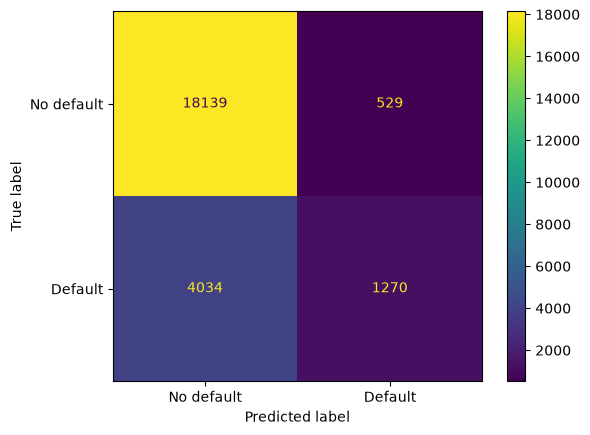

In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

predictions = cross_val_predict(logreg, X_train, y_train, cv=cv)
ConfusionMatrixDisplay.from_predictions(y_train, predictions, display_labels=["No default", "Default"])

## Logistic regression baseline

- Logistic regression with default settings (max_iter=1000 only so it finishes). No tuning yet.
- Same pipeline, folds and metrics as the dummy baseline.
- Mean over 5 folds: F1 0.358 (std 0.013), recall 0.239, precision 0.707, ROC AUC 0.725, accuracy 0.810.
- It beats the dummy on every metric, and the scores are stable across folds.
- Recall is low. It catches 1,270 of 5,304 defaulters and misses 4,034. Improving recall is the main goal for Milestone 3.

## Next steps (Milestone 3)

- Add k-nearest neighbours, a decision tree and a random forest using the same pipeline and folds.
- Tune a small number of settings for each model using cross-validation on the training set.
- Try class_weight="balanced" and a different decision threshold to improve recall.
- Look at which clients the models get wrong, and compare results across SEX, AGE and MARRIAGE.